In [1]:
import os, sys
cur_directory = os.getcwd()
project_folder = os.path.abspath(os.path.join(cur_directory, os.pardir, os.pardir))
save_directory = os.path.join(cur_directory, 'saved')
sys.path.append(os.path.join(project_folder, 'analysis-suite'))

In [13]:
import numpy as np
import matplotlib as mpl
from matplotlib import pyplot as plt
import analyses as als
import datasets as ds
import models as mds
import tools
from random import sample
from tqdm import tqdm
from argparse import Namespace
from time import gmtime, strftime
import pickle

## Params

In [14]:
group_size_array = np.arange(2,93)[::5] + 1
N_training_repeats = 10  # a different group of neurons will be selected for each
cg_params = {
    "order": 1,
}
N_meta_neurons=20

critic_params = {
    "hidden_dim": 32,
    "embed_dim": 30,
    "layers": 2,
    "activation": "tanh",
}
opt_params = {"track_quantities": False, "quiet": True, "iterations": 1}
mi_measurement_params = {"quiet": True, "batch_size": 500, "N_batches": 500}

V_width = 1
V_E_buffer = 0
E_width = 1

train_fraction = 0.5
samp_keep = 1

# Put variable names here for parameters we want saved.
save_vars = {
    "mi_measurement_params",
    "group_size_array",
    "N_training_repeats",
    "cg_params",
    "critic_params",
    "opt_params",
    "V_width",
    "V_E_buffer",
    "E_width",
    "train_fraction",
    "samp_keep",
    "neuron_inds",
}

## Prepare data

In [15]:
data_path = os.path.join(project_folder, 'data', 'nat_scenes_data')
D = ds.DataNatScenes(data_path, mov_ind=4)
print(f'current stimulus is {D.movname}')
mov_ind = D.mov_ind
save_vars.add('mov_ind')

AttributeError: 'int' object has no attribute 'path'

## Run analysis

In [16]:
experiment_dims = (len(group_size_array), N_training_repeats)
mi_averages_test = np.zeros(experiment_dims)
mi_averages_train = np.zeros(experiment_dims)
mi_stdevs_train = np.zeros(experiment_dims)
mi_stdevs_test = np.zeros(experiment_dims)


neuron_inds_across_trials = np.zeros(experiment_dims, dtype=object)
coarse_grainer_array = np.zeros(experiment_dims, dtype=object)
critic_function_array = np.zeros(experiment_dims, dtype=object)
train_points = np.zeros(experiment_dims, dtype=object)
test_points = np.zeros(experiment_dims, dtype=object)
save_vars.update(
    {
        "mi_averages_train",
        "mi_averages_test",
        "mi_stdevs_train",
        "mi_stdevs_test",
        "neuron_inds_across_trials",
        "train_points",
        "test_points",
    }
)


for i, population_size in tqdm(enumerate(group_size_array)):
    for training_repeat in range(N_training_repeats):
        # coarse_grainer = mds.PolynomialLayer(output_dim=population_size, **cg_params)
        coarse_grainer = mds.PolynomialLayer(output_dim=N_meta_neurons, **cg_params)
        critic_function = mds.SeparableCritic(**critic_params)

        # make current neuron subset
        D.reset()
        D.trim(20)
        neuron_inds = sample(range(D.N), k=population_size)
        neuron_inds_across_trials[i, training_repeat] = neuron_inds
        D.subset_features(neuron_inds)
        V, E = D.create_V_and_E_datasets(V_width, V_E_buffer, E_width, samp_keep)

        # make training and test subsets
        current_train_points, current_test_points = tools.generate_train_test_indices(
            V.P, train_fraction
        )
        V.subset_points(current_train_points)
        E.subset_points(current_train_points)
        train_points[i, training_repeat] = current_train_points
        test_points[i, training_repeat] = current_test_points

        # Train current
        als.IB(
            X=V.X,
            Y=E.X,
            coarse_grainer=coarse_grainer,
            critic_function=critic_function,
            **opt_params
        )

        # Measure InfoNCE for train
        T_train = coarse_grainer(V.X.T).numpy().T
        mi_train = als.MI_NCE(
            X=T_train, Y=E.X, critic_function=critic_function, **mi_measurement_params
        )
        mi_averages_train[i, training_repeat] = mi_train["mi"]
        mi_stdevs_train[i, training_repeat] = mi_train["mi_stdev"]

        # Measure InfoNCE for test
        V.reset()
        E.reset()
        V.subset_points(current_test_points)
        E.subset_points(current_test_points)
        T_test = coarse_grainer(V.X.T).numpy().T
        mi_test = als.MI_NCE(
            X=T_test, Y=E.X, critic_function=critic_function, **mi_measurement_params
        )
        mi_averages_test[i, training_repeat] = mi_test["mi"]
        mi_stdevs_test[i, training_repeat] = mi_test["mi_stdev"]

        coarse_grainer_array[i, training_repeat] = coarse_grainer
        critic_function_array[i, training_repeat] = critic_function

19it [05:17, 16.73s/it]


## Save

In [6]:
# select variables
coarse_grainer_type = type(coarse_grainer_array[0, 0])
critic_type = type(critic_function_array[0, 0])
save_vars.update({'coarse_grainer_type', 'critic_type'})
local_dict = locals()
output_data = {k: local_dict[k] for k in save_vars}

In [7]:
# save things
# timestamp = strftime("%Y.%m.%d %Hh %Mm %Ss.dat",gmtime())
# full_file_path = os.path.join(save_directory, strftime("%Y.%m.%d %Hh %Mm %Ss",gmtime())+'.dat')
# full_file_path = os.path.join(save_directory, 'random groups all.dat')
full_file_path = os.path.join(save_directory, f'random groups all tau={V_E_buffer+E_width}.dat')
os.makedirs(os.path.dirname(full_file_path), exist_ok=True)
with open(full_file_path, 'wb+') as f:
            pickle.dump(output_data, f)
tools.record_parameters(full_file_path, output_data)

## Reload and plot

In [ ]:
# load_path = project_folder + '/analyses/mutual info vs group size/saved/random groups high iter with cg tau=1.dat'

with open(load_path, 'rb') as f:
    data_dict = pickle.load(f)
data = Namespace(**data_dict)

import pym_estimate as pym

In [9]:
data_dict.keys()

dict_keys(['N_training_repeats', 'critic_params', 'V_width', 'mi_averages_train', 'coarse_grainer_type', 'group_size_array', 'mi_stdevs_test', 'mi_stdevs_train', 'E_width', 'opt_params', 'mov_ind', 'neuron_inds', 'cg_params', 'neuron_inds_across_trials', 'train_fraction', 'critic_type', 'samp_keep', 'train_points', 'test_points', 'mi_averages_test', 'V_E_buffer', 'mi_measurement_params'])

In [10]:
average_test = np.average(data.mi_averages_test, axis=1)
average_train = np.average(data.mi_averages_train, axis=1)
trial_variance_test = np.diag(np.cov(data.mi_averages_test))
trial_variance_train = np.diag(np.cov(data.mi_averages_train))
full_stdevs_train = np.sqrt(np.sum(data.mi_stdevs_train**2, axis=1) + trial_variance_train)
full_stdevs_test = np.sqrt(np.sum(data.mi_stdevs_test**2, axis=1) + trial_variance_test)

In [11]:
x = data.group_size_array
fit_train = als.linear_regress(x, data.mi_averages_train, data.mi_stdevs_train)
fit_test = als.linear_regress(x, data.mi_averages_test, data.mi_stdevs_test)

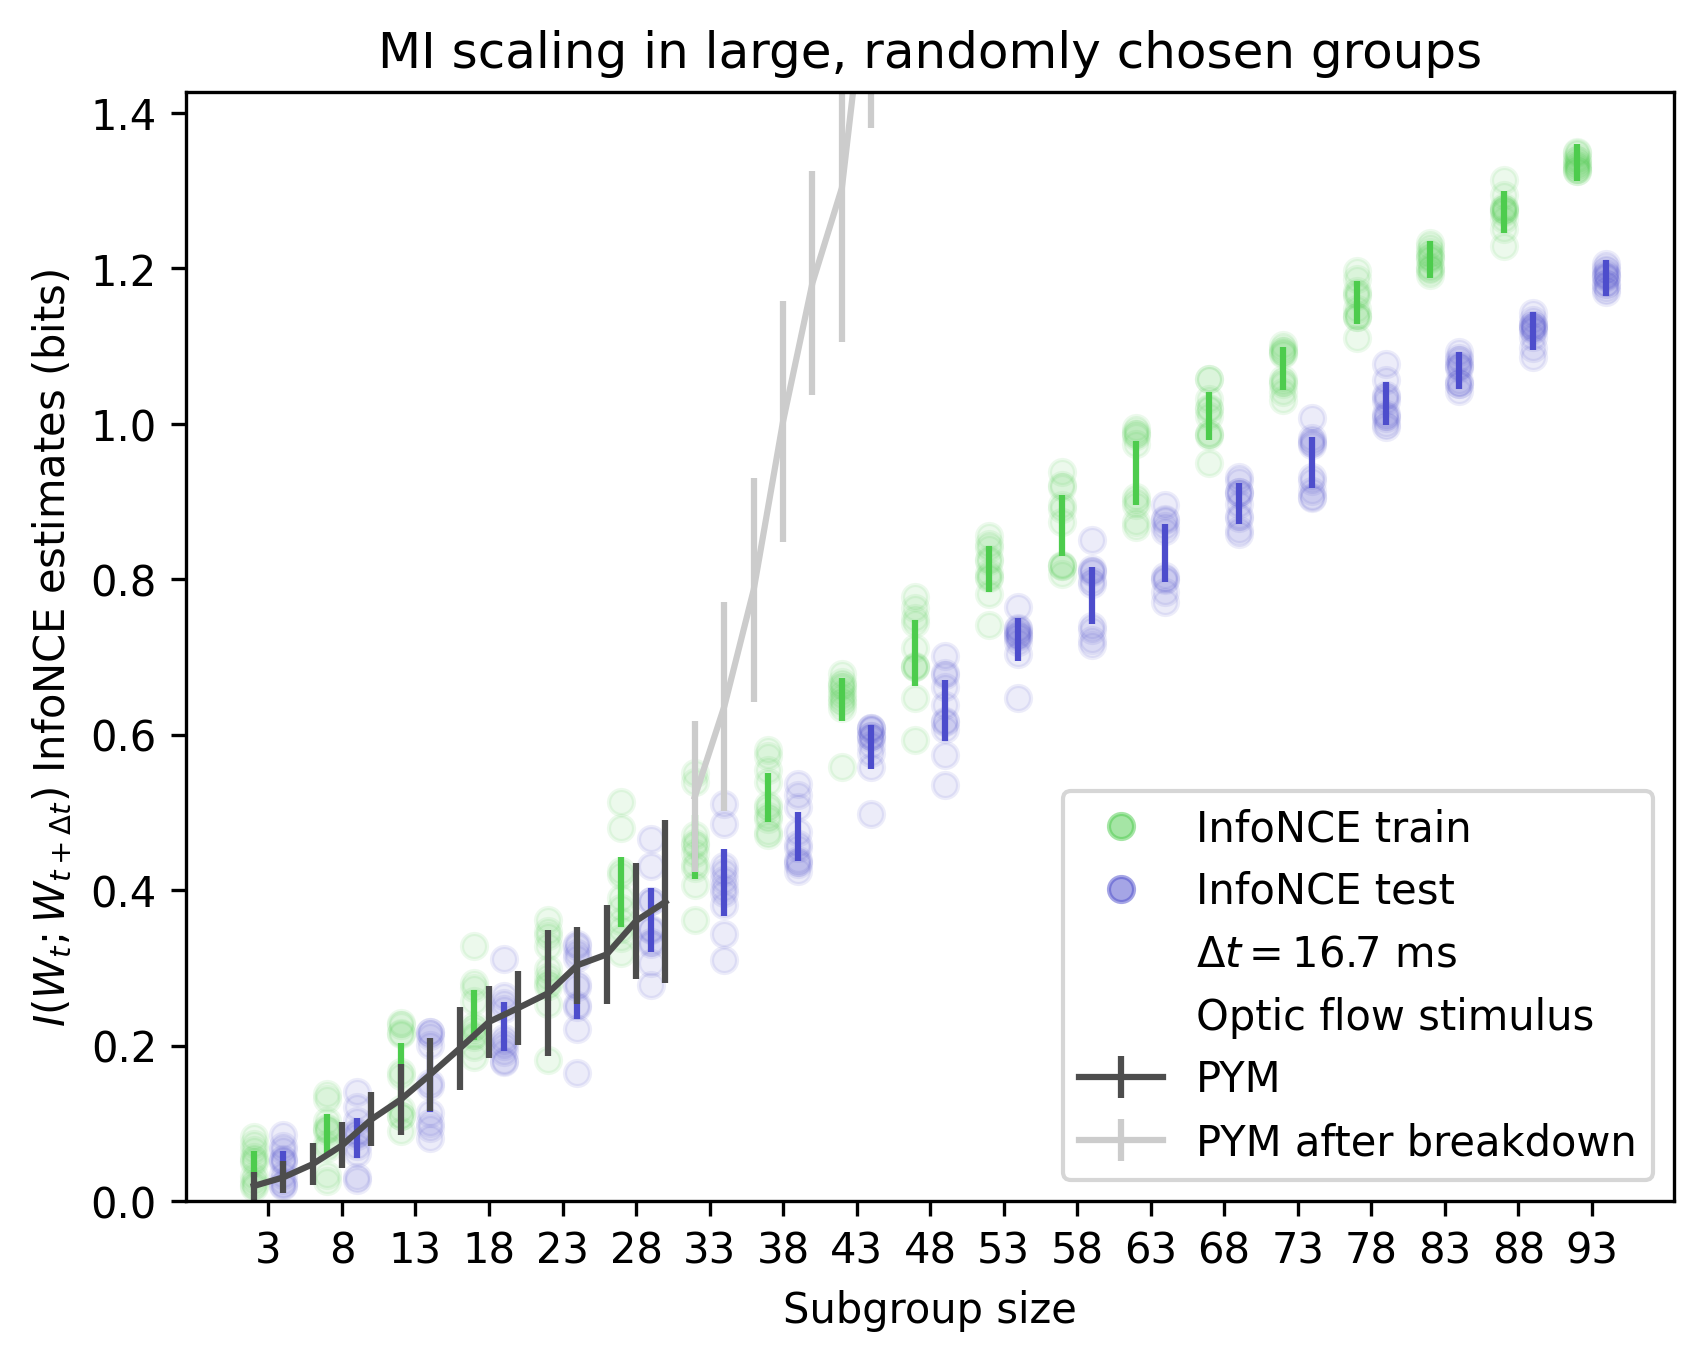

In [12]:
c1 = 0.3
c2 = 0.8
alp = 0.1
fig, ax = plt.subplots(dpi=300)

os = 1
# plt.plot(x, average_train/np.log(2), color=(c1,c2,c1), label='InfoNCE train')
plt.plot(x-os, data.mi_averages_train/np.log(2),'o', color=(c1,c2,c1,alp))
# plt.plot(x, average_test/np.log(2), color=(c1,c1,c2), label='InfoNCE test');
plt.plot(x+os, data.mi_averages_test/np.log(2),'o', color=(c1,c1,c2,alp))
plt.errorbar(x-os, average_train/np.log(2), yerr=full_stdevs_train, linestyle='', color=(c1,c2,c1))
plt.errorbar(x+os, average_test/np.log(2), yerr=full_stdevs_test, linestyle='', color=(c1,c1,c2))

# plt.plot(x, fit_train["fit"](x)/np.log(2), color=(c1,c2,c1), label='train linear fit')
# plt.plot(x, fit_test["fit"](x)/np.log(2), color=(c1,c1,c2), label='test linear fit')

plt.plot([], [], 'o', color=(c1,c2,c1,0.5), label='InfoNCE train')
plt.plot([], [], 'o', color=(c1,c1,c2,0.5), label='InfoNCE test')
plt.plot([],[], color=(1,1,1), label=r'$\Delta t = 16.7$ ms')
plt.plot([],[], color=(1,1,1), label=r'Optic flow stimulus')

pym.plot_results(ax)

plt.ylim(ymin=0)
plt.title('MI scaling in large, randomly chosen groups')
plt.xlabel('Subgroup size')

ax.set_xticks(x)
plt.ylabel(r'$I(W_{t};W_{t+\Delta t})$ InfoNCE estimates (bits)')
plt.legend();

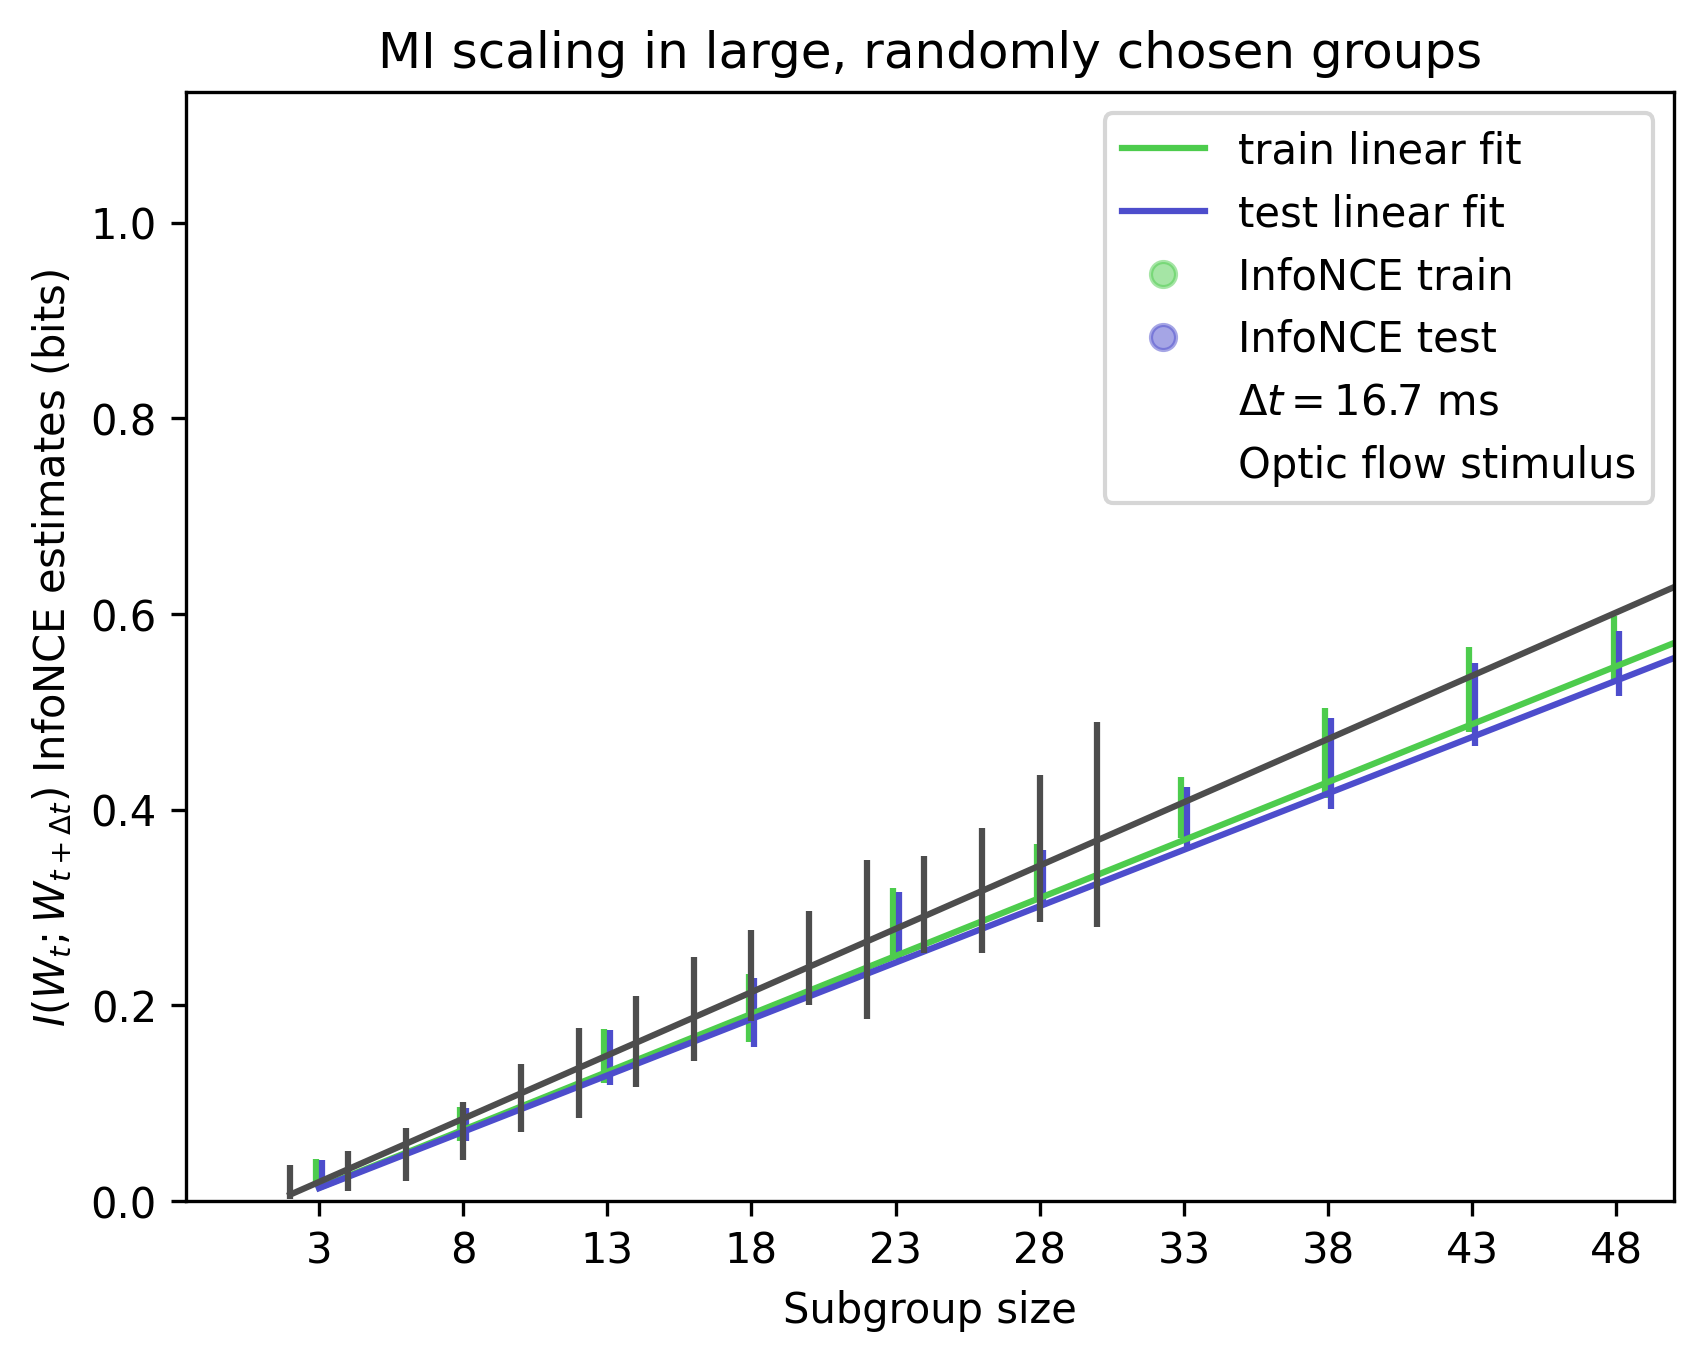

In [15]:
c1 = 0.3
c2 = 0.8
alp = 0.1
fig, ax = plt.subplots(dpi=300)

os = 0.1
# plt.plot(x, average_train/np.log(2), color=(c1,c2,c1), label='InfoNCE train')
# plt.plot(x-os, data.mi_averages_train/np.log(2),'o', color=(c1,c2,c1,alp))
# plt.plot(x, average_test/np.log(2), color=(c1,c1,c2), label='InfoNCE test');
# plt.plot(x+os, data.mi_averages_test/np.log(2),'o', color=(c1,c1,c2,alp))
plt.errorbar(x-os, average_train/np.log(2), yerr=full_stdevs_train, linestyle='', color=(c1,c2,c1))
plt.errorbar(x+os, average_test/np.log(2), yerr=full_stdevs_test, linestyle='', color=(c1,c1,c2))

plt.plot(x, fit_train["fit"](x)/np.log(2), color=(c1,c2,c1), label='train linear fit')
plt.plot(x, fit_test["fit"](x)/np.log(2), color=(c1,c1,c2), label='test linear fit')

pym.plot_linear_regress(ax)

plt.plot([], [], 'o', color=(c1,c2,c1,0.5), label='InfoNCE train')
plt.plot([], [], 'o', color=(c1,c1,c2,0.5), label='InfoNCE test')
plt.plot([],[], color=(1,1,1), label=r'$\Delta t = 16.7$ ms')
plt.plot([],[], color=(1,1,1), label=r'Optic flow stimulus')

plt.ylim(ymin=0)
plt.title('MI scaling in large, randomly chosen groups')
plt.xlabel('Subgroup size')

ax.set_xticks(x)
ax.set_xlim(xmax=50)
plt.ylabel(r'$I(W_{t};W_{t+\Delta t})$ InfoNCE estimates (bits)')
plt.legend();